# Awareness and Perceived Benefits of Intelligent Transport Technologies in Ghana

Analysis code for the manuscript *Awareness and Perceived Benefits of Intelligent Transport Technologies in
Ghana: Evidence from a University-Connected Sample* (submitted to *Case Studies on Transport Policy*).

The notebook follows the order of Section 4 of the paper. Every figure and table in the paper is produced
by exactly one section below; nothing else is computed.

| Notebook section | Paper | Output |
|---|---|---|
| 0. Setup and coding | §3.2 | raw export → 480 analysed responses |
| 1. Sample characteristics | §4.1, Table A1 | `outputs/tableA1_sample_characteristics.csv` |
| 2. Benefit ratings | §4.1, Figures 1–2 | `figures/benefit ranking.png`, `figures/likert_stacked.png` |
| 3. Familiarity and willingness by age and gender | §4.1–4.2, Figures 3, 6, 7, 8 | `figures/Age Group.png`, `gender_fam.png`, `gender_vs_willingness.png`, `age_use.png` |
| 4. Technology recognition | §4.1, Figure 4 | `figures/familiar_techs_bar.png` |
| 5. Awareness and income versus willingness | §4.2, Figures 9–10 | `figures/awareness_vs_willingness.png`, `income_vs_willingness.png` |
| 6. Cramér's V | §4.2, Table 1, Figure 5 | `outputs/table1_cramers_v.csv`, `figures/cramersv.png` |
| 7. Sociodemographic correlates (OLS) | §4.3, Table 2 | `outputs/table2_sociodemographic_correlates.csv` |
| 8. Respondent profiles (K-means) | §4.4, Figures 11–13 | `figures/fig12_attitudes.png` etc., `outputs/cluster_diagnostics.csv` |
| 9. Willingness–familiarity segments | §4.6, Table 3 | `outputs/table3_panelA.csv`, `table3_panelB_*.csv`, `table3_panelC.csv` |
| 10. Data checks | §3.2 | coverage of the codebook, multi-select audit |

**Input.** The de-identified survey export `data/ITS_Survey_Deidentified.xlsx` (in this repository): the raw
Microsoft Forms export with the time stamps, e-mail and name columns removed. The code also accepts the original
export, from which it drops those columns itself. Set the path in the first code cell or through the environment
variable `ITS_SURVEY`. The export has no stable header text, so columns are addressed by position (after the
metadata columns are removed).

## 0. Setup, codebook and data loading

In [1]:
import os
import re
import textwrap
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.colors import to_rgb
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

# Local copy of the raw export; the relative path is used when the local copy is not present
# (for example when the notebook is run from the public repository).
INPUT = Path(r"F:\网页下载(包含大论文数据)\大论文\参考文献\ITS Survey(1-494).xlsx")
FALLBACK = Path(os.environ.get("ITS_SURVEY", "data/ITS_Survey_Deidentified.xlsx"))
RAW_SURVEY = INPUT if INPUT.exists() else FALLBACK
if not RAW_SURVEY.exists():
    raise FileNotFoundError(f"survey file not found at {INPUT} or {FALLBACK}")

OUTPUT_DIR = Path("outputs")
FIGURE_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
N_CLUSTER_BOOTSTRAP = 50


def pct(n, total, digits=1):
    """Percentage rounded half up (conventional rounding, as in the manuscript tables)."""
    from decimal import Decimal, ROUND_HALF_UP
    value = Decimal(int(n)) * 100 / Decimal(int(total))          # exact, avoids 63.749999...
    return float(value.quantize(Decimal(10) ** -digits, rounding=ROUND_HALF_UP))


print(f"reading {RAW_SURVEY}")

d:\anaconda\D_anaconda3\lib\site-packages\statsmodels\tools\_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


reading F:\网页下载(包含大论文数据)\大论文\参考文献\ITS Survey(1-494).xlsx


In [2]:
# Metadata columns of the Forms export that are removed before analysis (they are absent from the
# de-identified file). Columns are then addressed by position, 0 = ID, 1 = consent item.
METADATA_COLUMNS = ["Start time", "Completion time", "Email", "Name", "Last modified time"]
RAW_COLUMNS = {
    "Consent": 1, "Familiarity": 2, "Technologies": 3, "Apps_Use_Freq": 4, "Challenges": 5,
    "Improve_ITS": 6, "Q1": 7, "Q2": 8, "Q3": 9, "Q4": 10, "Q5": 11, "Q6": 12,
    "Gov_Invest": 13, "Would_Use_ITS": 15, "Learn_More": 18, "GrewUp": 19, "Live": 20,
    "Age": 21, "Gender": 22, "Income": 23, "Education": 25,
}
CONSENT_YES = "I agree to participate in this survey."

# Numeric coding used for the regressions, Cramér's V and the cluster figures.
# "Prefer not to say" is treated as missing in the regressions (Table 2); the descriptive figures
# keep it as a category of its own.
CODEBOOK = {
    "Familiarity": {
        "Not at all familiar": 1,
        "Have heard the term but don't know what it means exactly": 2,
        "Have some understanding of it": 3,
        "Very familiar": 4,
    },
    "Apps_Use_Freq": {
        "Never": 1,
        "Rarely (couple of times a year or less)": 2,
        "Occasionally (couple of times per month or more)": 3,
        "Yes, frequently (few times per week or more)": 4,
    },
    "Would_Use_ITS": {"No": 1, "Maybe": 2, "Yes": 3},
    "Learn_More": {"No": 1, "Maybe": 2, "Yes": 3},
    "Improve_ITS": {"No": 1, "Not Sure": 2, "It depends": 2, "Yes": 3},
    "Age": {"18-24": 1, "25-34": 2, "35-44": 3, "45+": 4, "Prefer not to say": np.nan},
    "Gender": {"Male": 0, "Female": 1, "Non-binary": np.nan, "Prefer not to say": np.nan},
    "Income": {
        "No Income": 0, "Less than GHS 1,000": 1,
        "GHS 1,000 – 3,000": 2, "GHS 1,000 - 3,000": 2,
        "GHS 3,000 – 6,000": 3, "GHS 3,000 - 6,000": 3,
        "GHS 6,000 – 10,000": 4, "GHS 6,000 - 10,000": 4,
        "More than GHS 10,000": 5, "Prefer not to say": np.nan,
    },
    "Place": {"Village": 1, "Town": 2, "City": 3, "Prefer not to say": np.nan},
    "Education": {
        "Primary School": 1, "High School": 2, "Nursing Training": 2, "Teacher Training": 2,
        "University (Undergraduate)": 3,
        "University (undergraduate) and acquired skills (Graphic designer)": 3,
        "Currently at the University doing my degree": 3,
        "University (Graduate)": 4, "Masters": 4, "Doctorate": 5,
        "Prefer not to say": np.nan,
    },
}

# Section 4.6 uses a four-level coding of Improve_ITS that places "It depends" above "Not Sure".
IMPROVE_FOUR_LEVEL = {"No": 1, "Not Sure": 2, "It depends": 3, "Yes": 4}

BENEFIT_SCALE = {
    "Not Beneficial at all": 1, "Slightly Beneficial": 2, "Moderately Beneficial": 3,
    "Very Beneficial": 4, "Extremely Beneficial": 5,
}
BENEFIT_ITEMS = {
    "Q1": "Smart signals", "Q2": "Transit apps", "Q3": "Tolling",
    "Q4": "Enforcement cameras", "Q5": "GPS fleet management", "Q6": "Self-driving / connected vehicles",
}
GOV_INVEST = {
    "No, there are more important priorities": 1, "Not sure": 2,
    "Yes, but only moderately": 3, "Yes, a lot more": 4,
}
CHALLENGES = {
    "Traffic congestion": "CH_congestion", "Poor road conditions": "CH_roads",
    "Road safety issues": "CH_safety", "High transportation costs": "CH_cost",
    "Poor public transportation": "CH_transit",
    "Lack of pedestrian and cycling infrastructure": "CH_nmt", "Air pollution": "CH_air",
}
# Order of the seven options as they appear in Figure 4.
TECHNOLOGY_OPTIONS = [
    "Advanced transportation management systems (e.g. Uber, Bolt, etc.)",
    "Advanced traveler information systems (e.g. Google Maps, Apple Maps, etc.)",
    "Advanced public transportation systems (e.g. Bus/train arrival times, shuttle systems, "
    "fare payment planning, etc.)",
    "Business vehicle management (e.g. Hubtel Delivery Driver assist)",
    "Advanced urban transportation systems (e.g. Adaptive traffic signal control, smart parking "
    "systems, Changeable message signs, etc.)",
    "Advanced vehicle control systems (e.g. Cruise Control, Adaptive Cruise Control, Automatic "
    "Emergency Braking, etc.)",
]
NONE_OF_THE_ABOVE = "none of the above"

In [3]:
def normalise(value):
    if isinstance(value, str):
        return " ".join(value.replace("\xa0", " ").split()).strip()
    return value


def load_raw(path=RAW_SURVEY):
    """Read the export, drop metadata columns, and keep consenting respondents with the two key items."""
    raw = pd.read_excel(path)
    raw = raw.drop(columns=[c for c in METADATA_COLUMNS if c in raw.columns])
    raw = raw.apply(lambda col: col.map(normalise))
    raw.columns = [normalise(c) for c in raw.columns]
    n_all = len(raw)
    consent = raw[raw.columns[RAW_COLUMNS["Consent"]]] == CONSENT_YES
    raw = raw[consent]
    n_consent = len(raw)
    keep = [raw.columns[RAW_COLUMNS["Familiarity"]], raw.columns[RAW_COLUMNS["Would_Use_ITS"]]]
    raw = raw.dropna(subset=keep).reset_index(drop=True)
    print(f"{n_all} responses recorded; {n_all - n_consent} did not consent and "
          f"{n_consent - len(raw)} left the familiarity or willingness item blank; {len(raw)} analysed")
    return raw


def column(raw, name):
    return raw.columns[RAW_COLUMNS[name]]


def text(raw, name):
    """Raw answer strings for one item."""
    return raw[column(raw, name)]


def code_items(raw):
    names = ["Familiarity", "Apps_Use_Freq", "Improve_ITS", "Learn_More", "Would_Use_ITS"]
    return pd.DataFrame({n: text(raw, n).map(CODEBOOK[n]) for n in names})


def code_demographics(raw):
    return pd.DataFrame({
        "Age": text(raw, "Age").map(CODEBOOK["Age"]),
        "Female": text(raw, "Gender").map(CODEBOOK["Gender"]),
        "Income": text(raw, "Income").map(CODEBOOK["Income"]),
        "Education": text(raw, "Education").map(CODEBOOK["Education"]),
        "Live": text(raw, "Live").map(CODEBOOK["Place"]),
        "GrewUp": text(raw, "GrewUp").map(CODEBOOK["Place"]),
    })


def split_multiselect(value):
    if pd.isna(value):
        return []
    return [token.strip() for token in str(value).split(";") if token.strip()]


raw = load_raw()
items = code_items(raw)
demographics = code_demographics(raw)
benefits = pd.DataFrame({q: text(raw, q).map(BENEFIT_SCALE) for q in BENEFIT_ITEMS})
items["UseYes"] = (items["Would_Use_ITS"] == 3).astype(int)
N = len(raw)
items.describe().round(3)

483 responses recorded; 3 did not consent and 0 left the familiarity or willingness item blank; 480 analysed


,Familiarity,Apps_Use_Freq,Improve_ITS,Learn_More,Would_Use_ITS,UseYes
count,480.000,476.000,480.000,480.000,480.000,480.000
mean,2.044,2.987,2.617,2.815,2.842,0.875
std,0.974,0.882,0.516,0.458,0.448,0.331
min,1.000,1.000,1.000,1.000,1.000,0.000
25%,1.000,2.000,2.000,3.000,3.000,1.000
50%,2.000,3.000,3.000,3.000,3.000,1.000
75%,3.000,4.000,3.000,3.000,3.000,1.000
max,4.000,4.000,3.000,3.000,3.000,1.000


## 1. Sample characteristics (Section 4.1, Table A1)

Counts and percentages are based on all 480 respondents. The cell also prints the headline figures quoted in
Sections 4.1 and 5: the share with no working understanding of ITS (levels 1 and 2), and willingness with and
without the conditional ("Maybe") responses.

In [4]:
TABLE_A1 = [
    ("Gender", "Gender", ["Male", "Female", "Non-binary", "Prefer not to say"]),
    ("Age", "Age", ["18-24", "25-34", "35-44", "45+", "Prefer not to say"]),
    ("Monthly household net income", "Income",
     ["Less than GHS 1,000", "GHS 1,000 – 3,000", "GHS 3,000 – 6,000", "GHS 6,000 – 10,000",
      "More than GHS 10,000", "No Income", "Prefer not to say"]),
    ("Education", "Education",
     ["Primary School", "Nursing Training", "Teacher Training", "High School",
      "University (Undergraduate)", "University (Graduate)", "Prefer not to say"]),
    ("Current residence", "Live", ["Village", "Town", "City", "Prefer not to say"]),
    ("Place of upbringing", "GrewUp", ["Village", "Town", "City", "Prefer not to say"]),
    ("Familiarity with ITS", "Familiarity", list(CODEBOOK["Familiarity"])),
]

rows = []
for block, name, levels in TABLE_A1:
    # a blank answer is reported together with "Prefer not to say"
    answers = text(raw, name).fillna("Prefer not to say")
    # income labels in the export use either an en dash or a hyphen; education has free-text variants
    # that the codebook folds into the main levels. Both are harmonised here through the codebook.
    if name == "Income":
        answers = answers.map(lambda v: v.replace(" - ", " – ") if isinstance(v, str) else v)
    if name == "Education":
        # free-text variants are folded into the two university rows through their codebook value
        fold = {3: "University (Undergraduate)", 4: "University (Graduate)", 5: "University (Graduate)"}
        answers = answers.map(lambda v: v if v in levels else fold.get(CODEBOOK["Education"].get(v), v))
    counts = answers.value_counts()
    for level in levels:
        n = int(counts.get(level, 0))
        rows.append({"block": block, "category": level, "n": n, "pct": pct(n, N)})
    other = int(counts.drop(index=[l for l in levels if l in counts.index]).sum())
    if other:
        rows.append({"block": block, "category": "Other / unmapped", "n": other, "pct": pct(other, N)})

table_a1 = pd.DataFrame(rows)
table_a1.to_csv(OUTPUT_DIR / "tableA1_sample_characteristics.csv", index=False)
print(table_a1.to_string(index=False))

fam = items["Familiarity"]
will = items["Would_Use_ITS"]
print(f"\nno working understanding of ITS (levels 1-2): {(fam <= 2).mean() * 100:.1f}%")
print(f"very familiar: {(fam == 4).mean() * 100:.1f}%")
print(f"willing to use (Yes): {(will == 3).mean() * 100:.1f}%")
print(f"willing including Maybe: {(will >= 2).mean() * 100:.1f}%")
print(f"aged 18-34: {demographics['Age'].isin([1, 2]).mean() * 100:.1f}%")

                       block                                                 category   n  pct
                      Gender                                                     Male 242 50.4
                      Gender                                                   Female 230 47.9
                      Gender                                               Non-binary   2  0.4
                      Gender                                        Prefer not to say   6  1.3
                         Age                                                    18-24 279 58.1
                         Age                                                    25-34 100 20.8
                         Age                                                    35-44  62 12.9
                         Age                                                      45+  28  5.8
                         Age                                        Prefer not to say  11  2.3
Monthly household net income                      

## 2. Perceived benefits (Section 4.1, Figures 1–2)

Six benefit items rated from 1 = Not Beneficial at all to 5 = Extremely Beneficial.

       mean  count    std     se
item                            
Q1    3.769  480.0  0.869  0.040
Q2    3.773  480.0  1.046  0.048
Q3    3.627  480.0  1.136  0.052
Q4    4.083  480.0  0.991  0.045
Q5    4.004  480.0  0.956  0.044
Q6    3.131  480.0  1.295  0.059


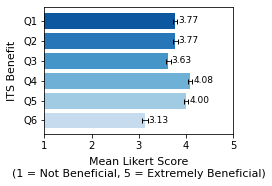

In [5]:
summary = benefits.agg(["mean", "count", "std"]).T
summary["se"] = summary["std"] / np.sqrt(summary["count"])
summary.index.name = "item"
summary.round(3).to_csv(OUTPUT_DIR / "fig1_benefit_means.csv")
print(summary.round(3).to_string())

# Figure 1 - mean rating per item with standard errors
order = list(BENEFIT_ITEMS)
colours = plt.cm.Blues_r(np.linspace(0.15, 0.75, len(order)))
fig, ax = plt.subplots(figsize=(3.6, 2.8))
y = np.arange(len(order))
ax.barh(y, summary.loc[order, "mean"], color=colours, xerr=summary.loc[order, "se"],
        error_kw=dict(ecolor="black", elinewidth=0.8, capsize=2.5))
for i, q in enumerate(order):
    ax.text(summary.loc[q, "mean"] + 0.07, i, f"{summary.loc[q, 'mean']:.2f}", va="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlim(1, 5)
ax.set_xlabel("Mean Likert Score\n(1 = Not Beneficial, 5 = Extremely Beneficial)", fontsize=11, labelpad=6)
ax.set_ylabel("ITS Benefit", fontsize=11, labelpad=6)
plt.tight_layout(pad=1.5)
fig.savefig(FIGURE_DIR / "benefit ranking.png", bbox_inches="tight")
plt.show()

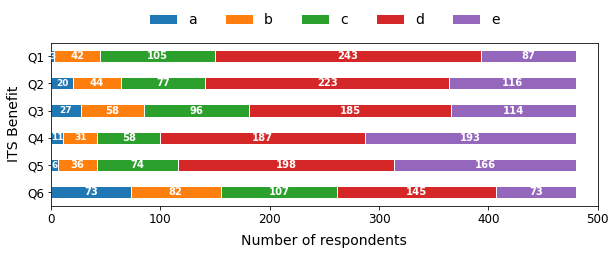

In [6]:
# Figure 2 - stacked counts of the five rating levels per item
counts = pd.DataFrame({q: benefits[q].value_counts().reindex(range(1, 6), fill_value=0) for q in order}).T
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
labels = ["a", "b", "c", "d", "e"]


def ideal_text_color(hex_color):
    r, g, b = to_rgb(hex_color)
    return "black" if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.6 else "white"


fig, ax = plt.subplots(figsize=(8.8, 3.8))
left = np.zeros(len(order))
for score in range(1, 6):
    values = counts[score].values
    bars = ax.barh(order, values, left=left, color=palette[score - 1], edgecolor="white",
                   height=0.45, label=labels[score - 1])
    for bar, n in zip(bars, values):
        if n > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + bar.get_height() / 2, f"{n}",
                    ha="center", va="center", color=ideal_text_color(palette[score - 1]),
                    fontsize=9 if bar.get_width() < 35 else 10, fontweight="bold")
    left += values
ax.invert_yaxis()
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5, frameon=False, fontsize=14)
ax.set_xlabel("Number of respondents", fontsize=14, labelpad=8)
ax.set_ylabel("ITS Benefit", fontsize=14, labelpad=6)
xmax = int(np.ceil(counts.sum(axis=1).max() / 100) * 100)
ax.set_xlim(0, xmax)
ax.set_xticks(range(0, xmax + 1, 100))
ax.tick_params(labelsize=12)
plt.tight_layout(pad=1.6)
fig.savefig(FIGURE_DIR / "likert_stacked.png", bbox_inches="tight")
plt.show()

## 3. Familiarity and willingness by age and gender (Sections 4.1–4.2, Figures 3, 6, 7, 8)

Grouped bars of the within-group percentage distribution. "Prefer not to say" is shown as a group of its own;
gender groups non-binary and undisclosed answers as "Other".

--- Familiarity by Age (row %) ---
                     n     1     2     3     4
Age                                           
Prefer not to say   11  45.5  18.2  36.4   0.0
18-24              279  34.1  36.6  21.5   7.9
25-34              100  35.0  34.0  15.0  16.0
35-44               62  35.5  32.3  21.0  11.3
45+                 28  50.0  17.9  28.6   3.6


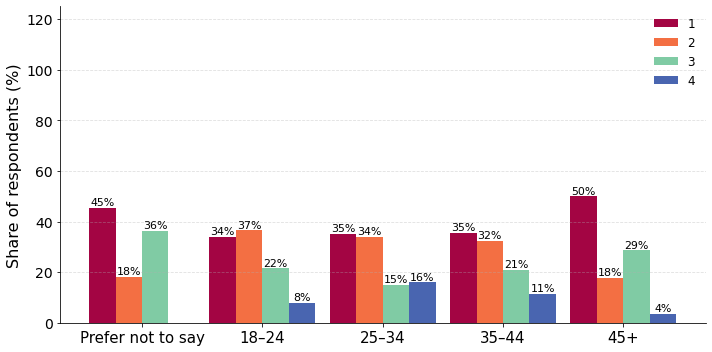

--- Familiarity by Gender (row %) ---
          n     1     2     3     4
Gender                             
Male    242  33.1  34.3  19.0  13.6
Female  230  37.8  33.9  22.6   5.7
Other     8  50.0  25.0  25.0   0.0


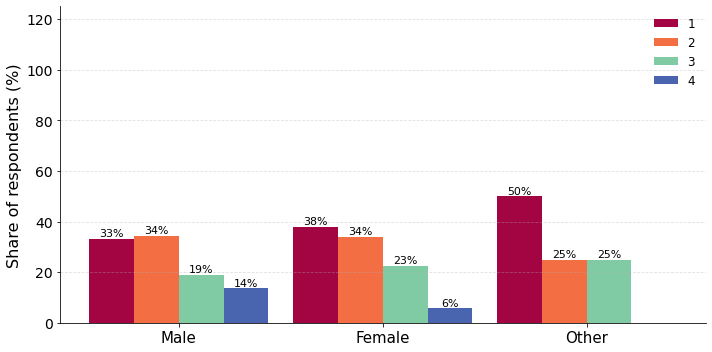

--- UseYes by Gender (row %) ---
          n     0     1
Gender                 
Male    242  10.3  89.7
Female  230  14.3  85.7
Other     8  25.0  75.0


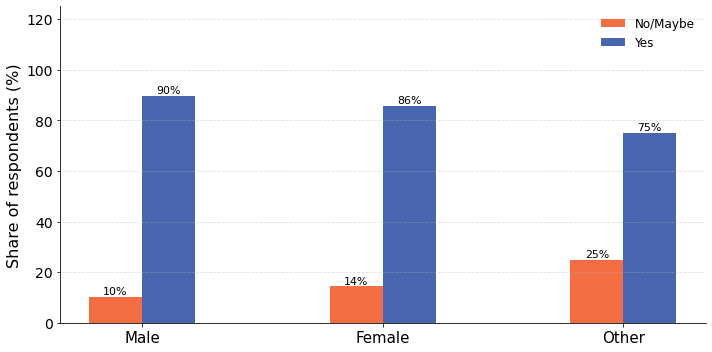

--- UseYes by Age (row %) ---
                     n     0     1
Age                               
Prefer not to say   11  27.3  72.7
18-24              279  10.8  89.2
25-34              100   7.0  93.0
35-44               62  14.5  85.5
45+                 28  39.3  60.7


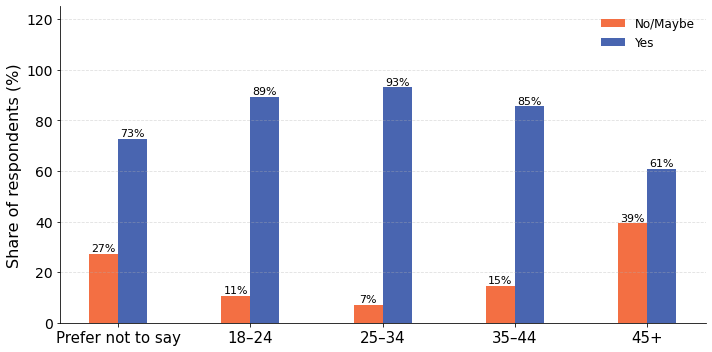

In [7]:
plot_frame = pd.DataFrame({
    "Age": text(raw, "Age").fillna("Prefer not to say"),
    "Gender": text(raw, "Gender").map(lambda g: g if g in ("Male", "Female") else "Other"),
    "Familiarity": items["Familiarity"].astype(int),
    "UseYes": items["UseYes"],
})

PALETTE_FAM = {1: "#a30543", 2: "#f36f43", 3: "#80cba4", 4: "#4965b0"}
PALETTE_BIN = {0: "#f36f43", 1: "#4965b0"}
LEVELS = {
    "Age": ["Prefer not to say", "18-24", "25-34", "35-44", "45+"],
    "Gender": ["Male", "Female", "Other"],
    "Familiarity": [1, 2, 3, 4],
    "UseYes": [0, 1],
}
LABELS = {
    "Age": {v: v.replace("-", "–") for v in LEVELS["Age"]},
    "Gender": {v: v for v in LEVELS["Gender"]},
    "Familiarity": {v: str(v) for v in LEVELS["Familiarity"]},
    "UseYes": {0: "No/Maybe", 1: "Yes"},
}


def grouped_bar(frame, group_var, target_var, palette, figname):
    sub = frame[[group_var, target_var]].dropna()
    ct = pd.crosstab(sub[group_var], sub[target_var]).reindex(
        index=LEVELS[group_var], columns=LEVELS[target_var], fill_value=0)
    prop = ct.div(ct.sum(axis=1), axis=0) * 100
    print(f"--- {target_var} by {group_var} (row %) ---")
    print(pd.concat([ct.sum(axis=1).rename("n"), prop.round(1)], axis=1).to_string())

    x = np.arange(len(LEVELS[group_var]))
    k = len(LEVELS[target_var])
    width = 0.22
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, level in enumerate(LEVELS[target_var]):
        offset = (i - (k - 1) / 2) * width          # centre the group on the tick
        values = prop[level].values
        ax.bar(x + offset, values, width, color=palette[level], label=LABELS[target_var][level])
        for j, v in enumerate(values):
            if v > 3:
                ax.text(x[j] + offset, v + 1, f"{v:.0f}%", ha="center", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[group_var][v] for v in LEVELS[group_var]], fontsize=15)
    ax.tick_params(axis="x", labelsize=15)
    ax.tick_params(axis="y", labelsize=14)
    ax.set_ylabel("Share of respondents (%)", fontsize=16)
    ax.set_ylim(0, 125)
    ax.legend(frameon=False, fontsize=12)
    ax.yaxis.grid(True, linestyle="--", alpha=0.4)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    fig.savefig(FIGURE_DIR / figname, bbox_inches="tight")
    plt.show()


grouped_bar(plot_frame, "Age", "Familiarity", PALETTE_FAM, "Age Group.png")              # Figure 3
grouped_bar(plot_frame, "Gender", "Familiarity", PALETTE_FAM, "gender_fam.png")          # Figure 6
grouped_bar(plot_frame, "Gender", "UseYes", PALETTE_BIN, "gender_vs_willingness.png")    # Figure 7
grouped_bar(plot_frame, "Age", "UseYes", PALETTE_BIN, "age_use.png")                     # Figure 8

## 4. Technology recognition (Section 4.1, Figure 4)

Multiple responses allowed. Bars show the number of respondents selecting each option. The percentage in
parentheses is the share of all selections (as printed in the figure); the share of respondents, quoted in the
figure caption, is printed as well.

1202 selections by 480 respondents
 option                                                                                                                               label  n_respondents  pct_of_selections  pct_of_respondents
      1                                                                  Advanced transportation management systems (e.g. Uber, Bolt, etc.)            348               29.0                72.5
      2                                                          Advanced traveler information systems (e.g. Google Maps, Apple Maps, etc.)            306               25.5                63.8
      3                 Advanced public transportation systems (e.g. Bus/train arrival times, shuttle systems, fare payment planning, etc.)            196               16.3                40.8
      4                                                                    Business vehicle management (e.g. Hubtel Delivery Driver assist)            135               11.2                

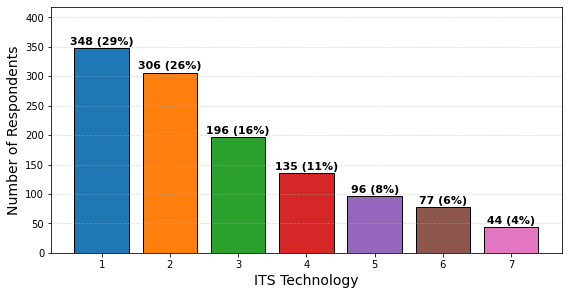

In [8]:
technologies = text(raw, "Technologies").apply(split_multiselect)
option_labels = TECHNOLOGY_OPTIONS + ["None of the above"]
lowered = [o.lower() for o in option_labels]
counts = pd.Series(0, index=option_labels, dtype=int)
unmatched = {}
for tokens in technologies:
    for t in tokens:
        key = t.strip().lower()
        if key in lowered:
            counts[option_labels[lowered.index(key)]] += 1
        else:
            unmatched[t] = unmatched.get(t, 0) + 1

total_selections = int(counts.sum())
recognition = pd.DataFrame({
    "option": range(1, len(option_labels) + 1),
    "label": option_labels,
    "n_respondents": counts.values,
    "pct_of_selections": [pct(c, total_selections) for c in counts.values],
    "pct_of_respondents": [pct(c, N) for c in counts.values],
})
recognition.to_csv(OUTPUT_DIR / "fig4_technology_recognition.csv", index=False)
print(f"{total_selections} selections by {N} respondents")
print(recognition.to_string(index=False))
if unmatched:
    print("unmatched tokens:", unmatched)

colours = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(recognition["option"], recognition["n_respondents"], color=colours, edgecolor="black")
for bar, n, p in zip(bars, recognition["n_respondents"], recognition["pct_of_selections"]):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 6, f"{n} ({p:.0f}%)", ha="center", fontsize=11,
            fontweight="bold")
ax.set_xticks(recognition["option"])
ax.set_xlabel("ITS Technology", fontsize=14)
ax.set_ylabel("Number of Respondents", fontsize=14)
ax.set_ylim(0, max(recognition["n_respondents"]) * 1.2)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "familiar_techs_bar.png", bbox_inches="tight")
plt.show()

## 5. Awareness and income versus willingness (Section 4.2, Figures 9–10)

                                                                                                n   Yes  Maybe   No
Have you ever heard of Intelligent Transportation Systems (ITS) prior to taking this survey?                       
Not at all familiar                                                                           171  84.8   11.7  3.5
Have heard the term but don't know what it means exactly                                      163  89.0    8.0  3.1
Have some understanding of it                                                                 100  87.0   10.0  3.0
Very familiar                                                                                  46  93.5    2.2  4.3


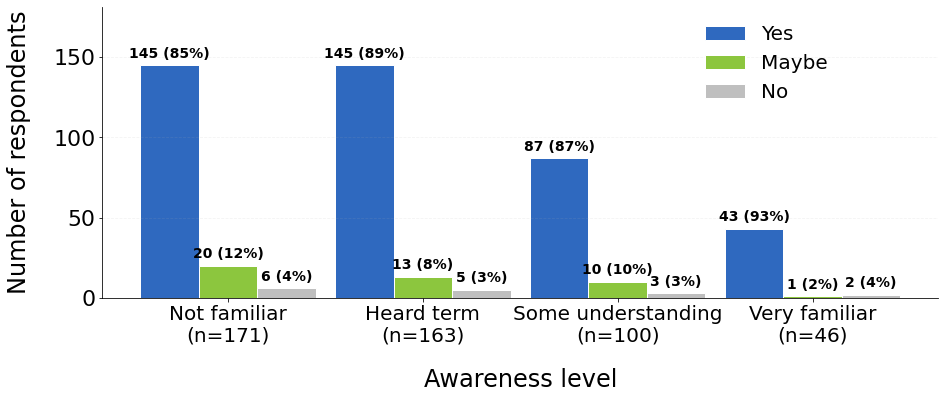

In [9]:
# Figure 9 - willingness by familiarity level (counts with row percentages)
order_awareness = list(CODEBOOK["Familiarity"])
short_names = ["Not familiar", "Heard term", "Some understanding", "Very familiar"]
order_will = ["Yes", "Maybe", "No"]

ct_counts = (pd.crosstab(text(raw, "Familiarity"), text(raw, "Would_Use_ITS"))
             .reindex(index=order_awareness, columns=order_will, fill_value=0))
row_n = ct_counts.sum(axis=1)
ct_pct = ct_counts.div(row_n, axis=0) * 100
print(pd.concat([row_n.rename("n"), ct_pct.round(1)], axis=1).to_string())

fig, ax = plt.subplots(figsize=(13.5, 6.8))
colors = {"Yes": "#2F69BF", "Maybe": "#8CC63E", "No": "#BFBFBF"}
x = np.arange(len(short_names)) * 0.8
bar_w = 0.24
ymax = ct_counts.values.max()
for i, resp in enumerate(order_will):
    bars = ax.bar(x + (i - 1) * bar_w, ct_counts[resp].values, width=bar_w, color=colors[resp],
                  edgecolor="white", label=resp)
    for b, n, p in zip(bars, ct_counts[resp].values, ct_pct[resp].values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + max(0.02 * ymax, 1.0),
                f"{n} ({p:.0f}%)", ha="center", va="bottom", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([f"{nm}\n(n={int(row_n.iloc[i])})" for i, nm in enumerate(short_names)], fontsize=20)
ax.set_ylabel("Number of respondents", fontsize=24, labelpad=22)
ax.set_xlabel("Awareness level", fontsize=24, labelpad=22)
ax.tick_params(axis="y", labelsize=22)
ax.set_ylim(0, ymax * 1.25)
ax.yaxis.grid(True, linestyle="--", alpha=0.15)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(fontsize=20, frameon=False, bbox_to_anchor=(0.7, 1), loc="upper left")
plt.tight_layout(rect=[0.02, 0.05, 1, 0.88])
fig.savefig(FIGURE_DIR / "awareness_vs_willingness.png", bbox_inches="tight")
plt.show()

                        n   Yes  Maybe    No
income                                      
No Income             238  87.8   10.1   2.1
Less than GHS 1,000    50  92.0    4.0   4.0
GHS 1,000 – 3,000      54  90.7    5.6   3.7
GHS 3,000 – 6,000      43  88.4   11.6   0.0
GHS 6,000 – 10,000     28  85.7    7.1   7.1
More than GHS 10,000   19  78.9    5.3  15.8
Prefer not to say      48  81.2   14.6   4.2


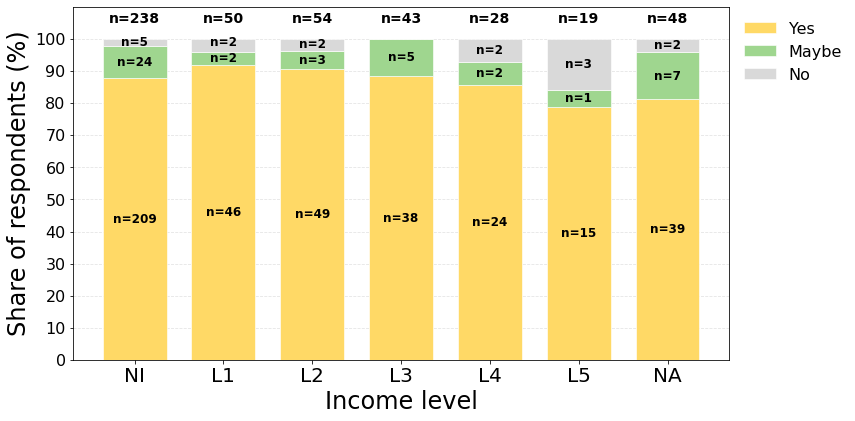

In [10]:
# Figure 10 - willingness by monthly income (stacked row percentages)
INCOME_ORDER = ["No Income", "Less than GHS 1,000", "GHS 1,000 – 3,000", "GHS 3,000 – 6,000",
                "GHS 6,000 – 10,000", "More than GHS 10,000", "Prefer not to say"]
INCOME_SHORT = dict(zip(INCOME_ORDER, ["NI", "L1", "L2", "L3", "L4", "L5", "NA"]))
WILL_ORDER = ["Yes", "Maybe", "No"]
PALETTE = {"Yes": "#FFD966", "Maybe": "#9FD68F", "No": "#D9D9D9"}

income = text(raw, "Income").map(lambda v: v.replace(" - ", " – ") if isinstance(v, str) else v)
frame = pd.DataFrame({"income": income, "will": text(raw, "Would_Use_ITS")}).dropna()
ct_counts = pd.crosstab(frame["income"], frame["will"]).reindex(index=INCOME_ORDER, columns=WILL_ORDER,
                                                               fill_value=0)
totals = ct_counts.sum(axis=1)
ct_pct = ct_counts.div(totals.replace(0, np.nan), axis=0).fillna(0) * 100
print(pd.concat([totals.rename("n"), ct_pct.round(1)], axis=1).to_string())

x = np.arange(len(INCOME_ORDER))
fig, ax = plt.subplots(figsize=(12, 7))
bottom = np.zeros(len(INCOME_ORDER))
for cat in WILL_ORDER:
    ax.bar(x, ct_pct[cat].values, bottom=bottom, width=0.72, color=PALETTE[cat], edgecolor="white",
           linewidth=0.6, label=cat)
    bottom += ct_pct[cat].values
MIN_GAP = 5
for i, inc in enumerate(INCOME_ORDER):
    cum, positions, labels = 0.0, [], []
    for cat in WILL_ORDER:
        pct, n = float(ct_pct.loc[inc, cat]), int(ct_counts.loc[inc, cat])
        if n:
            positions.append(cum + pct / 2)
            labels.append(f"n={n}")
        cum += pct
    for j in range(1, len(positions)):
        if positions[j] - positions[j - 1] < MIN_GAP:
            positions[j] = positions[j - 1] + MIN_GAP
    for yv, label in zip(np.clip(positions, 0, 100), labels):
        ax.text(x[i], yv, label, ha="center", va="center", fontsize=12, fontweight="bold")
    ax.text(x[i], 104, f"n={int(totals.loc[inc])}", ha="center", va="bottom", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([INCOME_SHORT[v] for v in INCOME_ORDER], fontsize=20)
ax.set_ylabel("Share of respondents (%)", fontsize=24)
ax.set_xlabel("Income level", fontsize=24)
ax.tick_params(axis="y", labelsize=16)
ax.set_ylim(0, 110)
ax.set_yticks(np.arange(0, 101, 10))
ax.yaxis.grid(True, linestyle="--", alpha=0.35)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=16, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.subplots_adjust(bottom=0.25, left=0.10, right=0.86, top=0.95)
fig.savefig(FIGURE_DIR / "income_vs_willingness.png", bbox_inches="tight")
plt.show()

## 6. Cramér's V (Section 4.2, Table 1 and Figure 5)

Pairwise Cramér's V on the categorical items. Gender is coded male / female / other; age, income, current
residence and place of upbringing keep "Prefer not to say" as a category of its own, and "No Income" is a
separate income level (as in Table A1 and Figure 10). Each pair is computed on the respondents who answered both
items.

              Familiarity  UseYes  Improve_ITS  Learn_More  Gender    Age  Income  Current_Live  Grew_Up
Familiarity         1.000   0.079        0.072       0.129   0.106  0.108   0.162         0.087    0.124
UseYes              0.079   1.000        0.235       0.222   0.078  0.225   0.097         0.086    0.095
Improve_ITS         0.072   0.235        1.000       0.158   0.089  0.099   0.097         0.041    0.041
Learn_More          0.129   0.222        0.158       1.000   0.108  0.294   0.247         0.129    0.114
Gender              0.106   0.078        0.089       0.108   1.000  0.288   0.183         0.235    0.187
Age                 0.108   0.225        0.099       0.294   0.288  1.000   0.405         0.232    0.242
Income              0.162   0.097        0.097       0.247   0.183  0.405   1.000         0.200    0.172
Current_Live        0.087   0.086        0.041       0.129   0.235  0.232   0.200         1.000    0.423
Grew_Up             0.124   0.095        0.041       0.

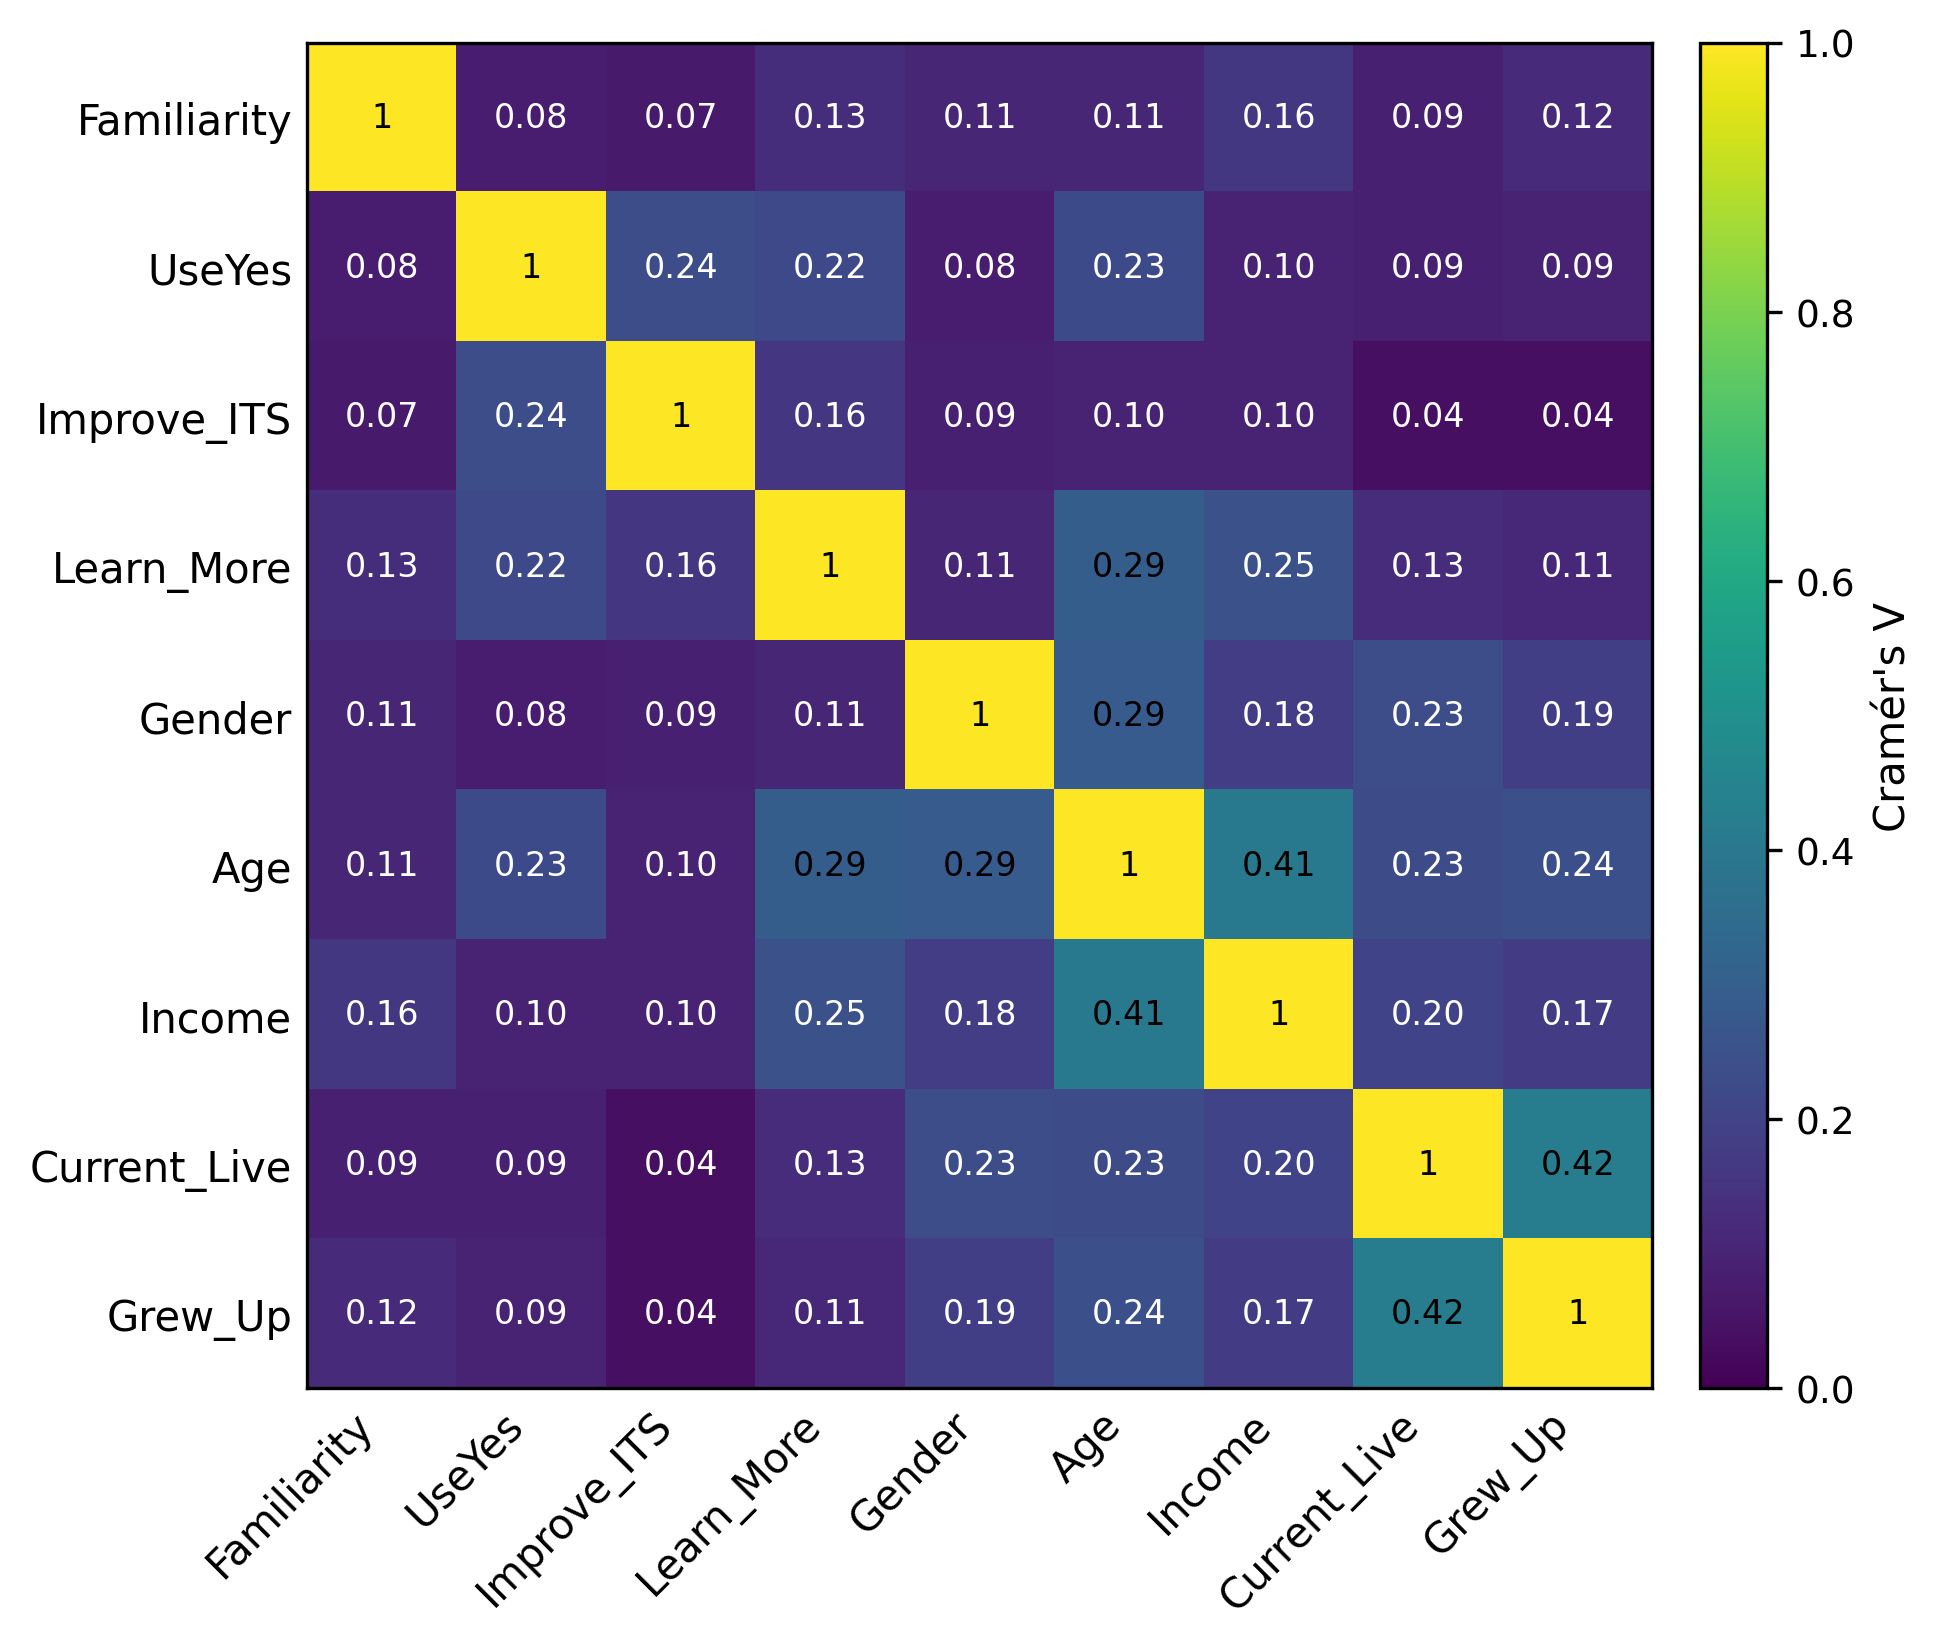

In [20]:
def cramers_v(ctab):
    chi2 = stats.chi2_contingency(ctab)[0]
    n = ctab.values.sum()
    r, k = ctab.shape
    return np.sqrt(chi2 / (n * max(1, min(k - 1, r - 1))))


cramer_frame = pd.DataFrame({
    "Familiarity": items["Familiarity"],
    "UseYes": items["UseYes"],
    "Improve_ITS": items["Improve_ITS"],
    "Learn_More": items["Learn_More"],
    "Gender": plot_frame["Gender"],
    "Age": text(raw, "Age"),
    "Income": income,
    "Current_Live": text(raw, "Live"),
    "Grew_Up": text(raw, "GrewUp"),
})
names = list(cramer_frame.columns)
M = np.eye(len(names))
for i, a in enumerate(names):
    for j, b in enumerate(names):
        if i != j:
            sub = cramer_frame[[a, b]].dropna()
            M[i, j] = cramers_v(pd.crosstab(sub[a], sub[b]))
table1 = pd.DataFrame(M, index=names, columns=names).round(3)
table1.to_csv(OUTPUT_DIR / "table1_cramers_v.csv")
print(table1.to_string())

# Figure: heat map of the matrix. The diagonal (V = 1) is masked so that the colour scale spans the
# off-diagonal associations; every cell is annotated with its value.
off_diagonal = M.copy()
np.fill_diagonal(off_diagonal, np.nan)
vmax = np.nanmax(off_diagonal)
fig, ax = plt.subplots(figsize=(6.5, 5.6), dpi=300)
im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="equal")
for i in range(len(names)):
    for j in range(len(names)):
        if i == j:
            ax.text(j, i, "1", ha="center", va="center", fontsize=8, color="black")
        else:
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if M[i, j] < 0.6 * vmax else "black")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=45, ha="right", fontsize=10)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=10)
ax.tick_params(length=0)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cbar.ax.tick_params(labelsize=9)
cbar.set_label("Cram\u00e9r's V", fontsize=10)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "cramersv.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Sociodemographic correlates of familiarity and willingness (Section 4.3, Table 2)

Two ordinary least squares regressions with the six characteristics entered simultaneously. The ordinal
outcomes are treated as numeric, so the coefficients are descriptive. Classical and HC3 p-values are both
reported; "Prefer not to say" answers are missing, giving n = 410 after listwise deletion.

In [12]:
DEMOGRAPHICS = ["Age", "Female", "Income", "Education", "Live", "GrewUp"]
OUTCOMES = {"Familiarity": "Familiarity (1-4)", "Would_Use_ITS": "Willingness (1-3)"}

frame = pd.concat([items[list(OUTCOMES)], demographics], axis=1).dropna()
coefficients, fit = {}, {}
for target, label in OUTCOMES.items():
    model = sm.OLS(frame[target], sm.add_constant(frame[DEMOGRAPHICS])).fit()
    robust = model.get_robustcov_results(cov_type="HC3")
    scale = frame[DEMOGRAPHICS + [target]].std()
    for position, variable in enumerate(DEMOGRAPHICS, start=1):
        entry = coefficients.setdefault(variable, {})
        entry[f"{label} b"] = round(model.params[variable], 3)
        entry[f"{label} beta"] = round(model.params[variable] * scale[variable] / scale[target], 3)
        entry[f"{label} p"] = round(model.pvalues[variable], 3)
        entry[f"{label} p_HC3"] = round(robust.pvalues[position], 3)
    fit[label] = {"R2": round(model.rsquared, 3), "model_p": round(model.f_pvalue, 4), "n": int(model.nobs)}

table2 = pd.DataFrame(coefficients).T
table2.to_csv(OUTPUT_DIR / "table2_sociodemographic_correlates.csv")
print(table2.to_string())
print()
print(pd.DataFrame(fit).T.to_string())

           Familiarity (1-4) b  Familiarity (1-4) beta  Familiarity (1-4) p  Familiarity (1-4) p_HC3  Willingness (1-3) b  Willingness (1-3) beta  Willingness (1-3) p  Willingness (1-3) p_HC3
Age                     -0.109                  -0.097                0.187                    0.236               -0.058                  -0.114                0.114                    0.153
Female                  -0.147                  -0.075                0.130                    0.129               -0.075                  -0.085                0.084                    0.112
Income                   0.015                   0.023                0.770                    0.805               -0.034                  -0.119                0.126                    0.152
Education                0.182                   0.103                0.068                    0.074                0.152                   0.191                0.001                    0.009
Live                     0.198          

## 8. Respondent profiles (Section 4.4, Figures 11–13)

K-means with k = 3 on standardised values of the items shown in each figure. Cluster indices are arbitrary, so
group names are attached by the rank of a group's overall profile. Silhouette scores for k = 2 to 5 and the
bootstrap adjusted Rand index (stability) are printed for each figure and saved to
`outputs/cluster_diagnostics.csv`, as stated in the paper.

In [13]:
AXIS_LABELS = {
    "Familiarity": "Familiarity with ITS",
    "Apps_Use_Freq": "Frequency of using\ntransport apps",
    "Improve_ITS": "Believes ITS improves\ntransport",
    "Learn_More": "Willing to learn\nmore about ITS",
    "Would_Use_ITS": "Willing to adopt ITS",
}
COLOURS = ["#4965b0", "#f36f43", "#4c9f70", "#a30543", "#7b5aa6"]


def label_for(name, inline=False):
    label = AXIS_LABELS.get(name, name.replace("_", " "))
    return label.replace("\n", " ") if inline else label


def fit_clusters(sub, k, random_state=RANDOM_STATE):
    X = StandardScaler().fit_transform(sub.values)
    return KMeans(n_clusters=k, random_state=random_state, n_init=10).fit_predict(X)


def silhouette_report(sub, ks=(2, 3, 4, 5)):
    X = StandardScaler().fit_transform(sub.values)
    scores = {}
    for k in ks:
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X)
        scores[k] = silhouette_score(X, labels)
        print(f"  k = {k}: silhouette = {scores[k]:.3f}")
    return scores


def cluster_stability(sub, k, n_boot=N_CLUSTER_BOOTSTRAP):
    rng = np.random.default_rng(RANDOM_STATE)
    baseline = fit_clusters(sub, k)
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(sub), len(sub))
        labels = fit_clusters(sub.iloc[idx], k)
        unique, first = np.unique(idx, return_index=True)
        values.append(adjusted_rand_score(baseline[unique], labels[first]))
    values = np.array(values)
    print(f"  bootstrap ARI: mean = {values.mean():.3f}, "
          f"5th-95th pct = [{np.percentile(values, 5):.3f}, {np.percentile(values, 95):.3f}]")
    return values


def profile(sub, labels):
    tmp = sub.copy()
    tmp["cluster"] = labels
    means = tmp.groupby("cluster").mean()
    normalised = (means - sub.min()) / (sub.max() - sub.min())
    counts = tmp["cluster"].value_counts().sort_index()
    return means, normalised, counts, (counts / counts.sum() * 100).round(1)


def describe_groups(normalised):
    order = normalised.mean(axis=1).sort_values(ascending=False).index.tolist()
    column_max, column_min = normalised.max(axis=0), normalised.min(axis=0)
    phrases = {}
    for cluster in order:
        row = normalised.loc[cluster]
        is_max = (row - column_max).abs() < 1e-9
        is_min = (row - column_min).abs() < 1e-9
        if is_max.all():
            phrases[cluster] = "highest on every dimension"
        elif is_min.all():
            phrases[cluster] = "lowest on every dimension"
        else:
            parts = []
            tops = [label_for(f, inline=True) for f in row[is_max].index][:2]
            bottoms = [label_for(f, inline=True) for f in row[is_min].index][:2]
            if tops:
                parts.append("highest on " + " and ".join(tops))
            if bottoms:
                parts.append("lowest on " + " and ".join(bottoms))
            phrases[cluster] = "; ".join(parts) if parts else "mid-range on all dimensions"
    return phrases, order


def legend_labels(normalised, counts, share, manual=None):
    """manual runs from the highest overall profile to the lowest."""
    phrases, order = describe_groups(normalised)
    labels = {}
    for rank, cluster in enumerate(order):
        name = manual[rank] if manual is not None and rank < len(manual) else phrases[cluster]
        labels[cluster] = f"{name} ({share[cluster]}% of respondents, N={counts[cluster]})"
    return labels, order


def radar_plot(features, labels, normalised, order, figname, wrap=52):
    angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
    angles += angles[:1]
    figure = plt.figure(figsize=(7.0, 7.8))
    ax = figure.add_axes([0.14, 0.33, 0.72, 0.61], polar=True)
    for i, cluster in enumerate(order):
        values = normalised.loc[cluster].tolist()
        values += values[:1]
        colour = COLOURS[i % len(COLOURS)]
        ax.plot(angles, values, linewidth=2.2, color=colour, label=textwrap.fill(labels[cluster], wrap))
        ax.fill(angles, values, alpha=0.14, color=colour)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([label_for(f) for f in features], fontsize=11)
    ax.tick_params(axis="x", pad=14)
    ax.set_ylim(0, 1)
    ax.set_rlabel_position(180.0 / len(features))
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=8, color="grey")
    ax.grid(alpha=0.5)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), frameon=False, fontsize=10, ncol=1,
              handlelength=1.8, labelspacing=0.8)
    figure.savefig(FIGURE_DIR / figname, dpi=300, bbox_inches="tight")
    plt.show()


def make_figure(frame, features, k, manual, figname, title):
    sub = frame[features].dropna()
    print(f"=== {title}  (n = {len(sub)}) ===")
    print("Silhouette scores:")
    scores = silhouette_report(sub)
    print(f"  k fixed at {k} for comparability across the figures")
    labels = fit_clusters(sub, k)
    ari = cluster_stability(sub, k)
    means, normalised, counts, share = profile(sub, labels)
    named, order = legend_labels(normalised, counts, share, manual=manual)
    radar_plot(features, named, normalised, order, figname)
    print("Group means on the original scales:")
    for cluster in order:
        print(f"* {named[cluster]}")
        print("    " + ", ".join(f"{label_for(c, inline=True)} = {means.loc[cluster, c]:.2f}" for c in means.columns))
    print()
    diagnostics = {"figure": figname, "n": len(sub), "k_used": k,
                   **{f"silhouette_k{k_}": round(v, 3) for k_, v in scores.items()},
                   "ari_mean": round(ari.mean(), 3), "ari_p5": round(np.percentile(ari, 5), 3),
                   "ari_p95": round(np.percentile(ari, 95), 3)}
    return {"labels": pd.Series(labels, index=sub.index), "means": means, "counts": counts,
            "share": share, "order": order, "diagnostics": diagnostics}

=== Figure 11 - attitudinal profiles  (n = 480) ===
Silhouette scores:
  k = 2: silhouette = 0.438
  k = 3: silhouette = 0.499
  k = 4: silhouette = 0.572
  k = 5: silhouette = 0.620
  k fixed at 3 for comparability across the figures
  bootstrap ARI: mean = 0.980, 5th-95th pct = [0.953, 1.000]


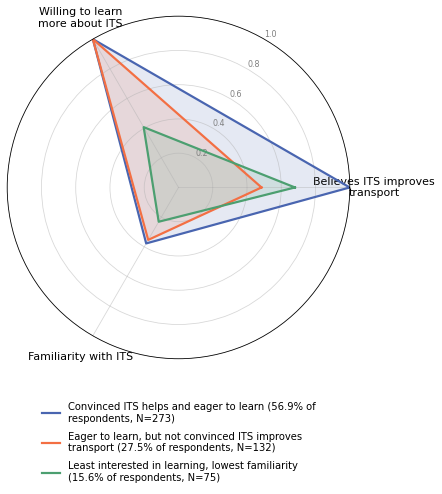

Group means on the original scales:
* Convinced ITS helps and eager to learn (56.9% of respondents, N=273)
    Believes ITS improves transport = 3.00, Willing to learn more about ITS = 3.00, Familiarity with ITS = 2.13
* Eager to learn, but not convinced ITS improves transport (27.5% of respondents, N=132)
    Believes ITS improves transport = 1.97, Willing to learn more about ITS = 3.00, Familiarity with ITS = 2.06
* Least interested in learning, lowest familiarity (15.6% of respondents, N=75)
    Believes ITS improves transport = 2.36, Willing to learn more about ITS = 1.81, Familiarity with ITS = 1.69

=== Figure 12 - technology-engagement profiles  (n = 476) ===
Silhouette scores:
  k = 2: silhouette = 0.477
  k = 3: silhouette = 0.396
  k = 4: silhouette = 0.454
  k = 5: silhouette = 0.469
  k fixed at 3 for comparability across the figures
  bootstrap ARI: mean = 0.882, 5th-95th pct = [0.292, 1.000]


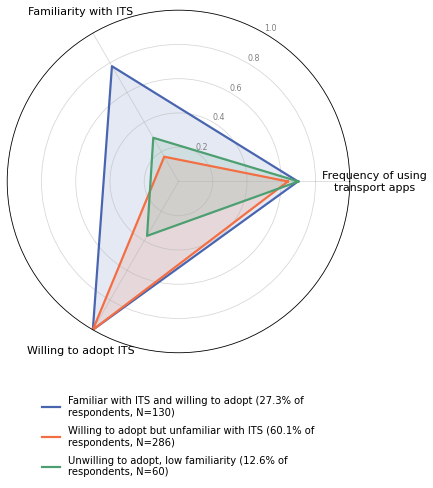

Group means on the original scales:
* Familiar with ITS and willing to adopt (27.3% of respondents, N=130)
    Frequency of using transport apps = 3.09, Familiarity with ITS = 3.33, Willing to adopt ITS = 3.00
* Willing to adopt but unfamiliar with ITS (60.1% of respondents, N=286)
    Frequency of using transport apps = 2.92, Familiarity with ITS = 1.50, Willing to adopt ITS = 3.00
* Unwilling to adopt, low familiarity (12.6% of respondents, N=60)
    Frequency of using transport apps = 3.10, Familiarity with ITS = 1.88, Willing to adopt ITS = 1.73

=== Figure 13 - adoption-readiness profiles  (n = 476) ===
Silhouette scores:
  k = 2: silhouette = 0.285
  k = 3: silhouette = 0.298
  k = 4: silhouette = 0.308
  k = 5: silhouette = 0.301
  k fixed at 3 for comparability across the figures
  bootstrap ARI: mean = 0.832, 5th-95th pct = [0.347, 1.000]


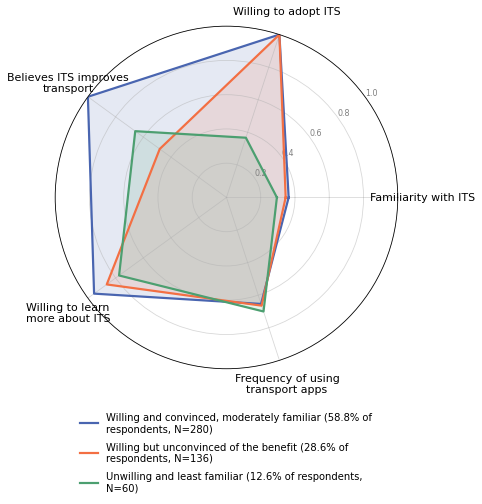

Group means on the original scales:
* Willing and convinced, moderately familiar (58.8% of respondents, N=280)
    Familiarity with ITS = 2.09, Willing to adopt ITS = 3.00, Believes ITS improves transport = 3.00, Willing to learn more about ITS = 2.91, Frequency of using transport apps = 2.96
* Willing but unconvinced of the benefit (28.6% of respondents, N=136)
    Familiarity with ITS = 2.04, Willing to adopt ITS = 3.00, Believes ITS improves transport = 1.96, Willing to learn more about ITS = 2.73, Frequency of using transport apps = 2.99
* Unwilling and least familiar (12.6% of respondents, N=60)
    Familiarity with ITS = 1.88, Willing to adopt ITS = 1.73, Believes ITS improves transport = 2.32, Willing to learn more about ITS = 2.55, Frequency of using transport apps = 3.10

                      figure   n  k_used  silhouette_k2  silhouette_k3  silhouette_k4  silhouette_k5  ari_mean  ari_p5  ari_p95
         fig12_attitudes.png 480       3          0.438          0.499          

In [14]:
FIGURES = {
    "fig12_attitudes.png": {                     # Figure 11 in the paper
        "title": "Figure 11 - attitudinal profiles",
        "features": ["Improve_ITS", "Learn_More", "Familiarity"],
        "labels": ["Convinced ITS helps and eager to learn",
                   "Eager to learn, but not convinced ITS improves transport",
                   "Least interested in learning, lowest familiarity"],
    },
    "fig13_tech_engagement.png": {               # Figure 12 in the paper
        "title": "Figure 12 - technology-engagement profiles",
        "features": ["Apps_Use_Freq", "Familiarity", "Would_Use_ITS"],
        "labels": ["Familiar with ITS and willing to adopt",
                   "Willing to adopt but unfamiliar with ITS",
                   "Unwilling to adopt, low familiarity"],
    },
    "fig14_adoption_readiness.png": {            # Figure 13 in the paper
        "title": "Figure 13 - adoption-readiness profiles",
        "features": ["Familiarity", "Would_Use_ITS", "Improve_ITS", "Learn_More", "Apps_Use_Freq"],
        "labels": ["Willing and convinced, moderately familiar",
                   "Willing but unconvinced of the benefit",
                   "Unwilling and least familiar"],
    },
}

cluster_items = items[["Familiarity", "Apps_Use_Freq", "Improve_ITS", "Learn_More", "Would_Use_ITS"]]
figures, diagnostics = {}, []
for figname, spec in FIGURES.items():
    figures[figname] = make_figure(cluster_items, spec["features"], 3, spec["labels"], figname, spec["title"])
    figures[figname]["means"].round(3).to_csv(OUTPUT_DIR / f"{figname[:-4]}_means.csv")
    diagnostics.append(figures[figname]["diagnostics"])
pd.DataFrame(diagnostics).to_csv(OUTPUT_DIR / "cluster_diagnostics.csv", index=False)
print(pd.DataFrame(diagnostics).to_string(index=False))


def lowest_group(result):
    lowest = result["order"][-1]
    return set(result["labels"][result["labels"] == lowest].index)


a = lowest_group(figures["fig13_tech_engagement.png"])
b = lowest_group(figures["fig14_adoption_readiness.png"])
print(f"\nlow-willingness group: Figure 12 N = {len(a)}, Figure 13 N = {len(b)}, shared = {len(a & b)}")

## 9. Willingness–familiarity segments (Section 4.6, Table 3)

Three segments are formed by crossing familiarity with stated willingness: HW-LF (willing, familiarity ≤ 2),
HW-HF (willing, familiarity ≥ 3) and Low-willingness (Maybe or No). They are compared on app-use frequency (M1),
the number of transport problems endorsed (M2) and the rated benefit of consumer-facing ITS (M3, item Q2).

In [15]:
LOW_FAMILIARITY_CUT = 2
MECHANISMS = ["USE", "DISSAT", "BEN_CONSUMER"]
MECHANISMS_PANEL_C = MECHANISMS + ["Q6"]
GROUPS = ["HW-LF", "HW-HF", "LowWill"]


def matches(tokens, options):
    lowered = {option.strip().lower() for option in options}
    return int(any(token.strip().lower() in lowered for token in tokens))


def encode_segments(raw):
    d = pd.DataFrame(index=raw.index)
    d["FAM"] = items["Familiarity"]
    d["WILL"] = items["Would_Use_ITS"]
    d["USE"] = items["Apps_Use_Freq"]
    d["IMPROVE_YES"] = (text(raw, "Improve_ITS") == "Yes").astype(int)
    for q in BENEFIT_ITEMS:
        d[q] = benefits[q]
    d["BEN_CONSUMER"] = d["Q2"]

    challenges = text(raw, "Challenges").apply(split_multiselect)
    for option, short in CHALLENGES.items():
        d[short] = challenges.apply(lambda t, o=option: matches(t, [o]))
    d["DISSAT"] = d[list(CHALLENGES.values())].sum(axis=1)
    d["DISSAT_TRANSIT"] = d["CH_transit"]

    d["TECH_NONE"] = technologies.apply(lambda t: matches(t, [NONE_OF_THE_ABOVE]))
    d["TECH_COUNT"] = technologies.apply(lambda tokens: sum(1 for t in tokens if t.lower() != NONE_OF_THE_ABOVE))

    d["LOWFAM"] = (d["FAM"] <= LOW_FAMILIARITY_CUT).astype(int)
    d["HIGHWILL"] = (d["WILL"] == 3).astype(int)
    d["GROUP"] = np.where(d["HIGHWILL"].eq(1) & d["LOWFAM"].eq(1), "HW-LF",
                          np.where(d["HIGHWILL"].eq(1), "HW-HF", "LowWill"))
    return d


d = encode_segments(raw)
counts = d["GROUP"].value_counts().reindex(GROUPS)
print(counts.to_frame("n").assign(pct=(counts / len(d) * 100).round(1)).to_string())

# Willingness by familiarity level: the range quoted in Sections 5 and 6 ("less than nine percentage points")
crosstab = pd.crosstab(d["FAM"], d["WILL"])
crosstab["all"] = crosstab.sum(axis=1)
crosstab["% willing"] = (crosstab[3] / crosstab["all"] * 100).round(1)
print("\nFamiliarity x willingness")
print(crosstab.to_string())
print(f"range of % willing across familiarity levels: {crosstab['% willing'].max() - crosstab['% willing'].min():.1f} points")

           n   pct
HW-LF    290  60.4
HW-HF    130  27.1
LowWill   60  12.5

Familiarity x willingness
WILL  1   2    3  all  % willing
FAM                             
1     6  20  145  171       84.8
2     5  13  145  163       89.0
3     3  10   87  100       87.0
4     2   1   43   46       93.5
range of % willing across familiarity levels: 8.7 points


In [16]:
# Panel A - segment profiles (Kruskal-Wallis across the three segments, epsilon-squared effect size)
def epsilon_squared(h, n, k):
    return (h - k + 1) / (n - k)


PANEL_A = [
    ("USE", "M1 app-use frequency (1-4)"),
    ("DISSAT", "M2 transport problems endorsed (0-7)"),
    ("BEN_CONSUMER", "M3 consumer-facing benefit (1-5)"),
    ("TECH_COUNT", "ITS technologies recognised (0-6)"),
    ("TECH_NONE", "selected 'None of the above'"),
]
rows = []
for variable, label in PANEL_A:
    samples = [d.loc[d.GROUP == g, variable].dropna() for g in GROUPS]
    h, p = stats.kruskal(*samples)
    n = sum(len(s) for s in samples)
    rows.append({"variable": variable, "label": label,
                 **{g: round(s.mean(), 3) for g, s in zip(GROUPS, samples)},
                 "H": round(h, 3), "p": round(p, 4), "epsilon2": round(epsilon_squared(h, n, 3), 4)})
panel_a = pd.DataFrame(rows)
panel_a.to_csv(OUTPUT_DIR / "table3_panelA.csv", index=False)
panel_a

,variable,label,HW-LF,HW-HF,LowWill,H,p,epsilon2
0,USE,M1 app-use frequency (1-4),2.916,3.092,3.100,4.590,0.1008,0.0055
1,DISSAT,M2 transport problems endorsed (0-7),3.231,3.769,3.350,5.996,0.0499,0.0084
2,BEN_CONSUMER,M3 consumer-facing benefit (1-5),3.800,4.062,3.017,37.301,0.0000,0.0740
3,TECH_COUNT,ITS technologies recognised (0-6),2.197,3.054,2.067,24.901,0.0000,0.0480
4,TECH_NONE,selected 'None of the above',0.128,0.008,0.100,15.521,0.0004,0.0283


In [17]:
# Panels B and C
def multinomial(d, predictors):
    frame = d[["GROUP"] + predictors].dropna()
    y = frame["GROUP"].map({"HW-HF": 0, "HW-LF": 1, "LowWill": 2})
    model = sm.MNLogit(y, sm.add_constant(frame[predictors].astype(float))).fit(disp=False)
    tables = {}
    for equation, label in enumerate(["HW-LF vs HW-HF", "LowWill vs HW-HF"]):
        params, se = model.params.iloc[:, equation], model.bse.iloc[:, equation]
        tables[label] = pd.DataFrame({
            "coef": params.round(3), "OR": np.exp(params).round(3),
            "CI_low": np.exp(params - 1.96 * se).round(3), "CI_high": np.exp(params + 1.96 * se).round(3),
            "p": model.pvalues.iloc[:, equation].round(4)})
    smallest = int(y.value_counts().min())
    info = {"n": int(model.nobs), "pseudo_R2": round(model.prsquared, 4), "LR_p": round(model.llr_pvalue, 4),
            "smallest_cell": smallest, "events_per_variable": round(smallest / len(predictors), 1)}
    return tables, info


def within_low_familiarity(d, predictors):
    frame = d[d["LOWFAM"] == 1][["HIGHWILL"] + predictors].dropna()
    model = smf.logit("HIGHWILL ~ " + " + ".join(predictors), data=frame).fit(disp=False)
    table = pd.DataFrame({
        "coef": model.params.round(3), "OR": np.exp(model.params).round(3),
        "CI_low": np.exp(model.params - 1.96 * model.bse).round(3),
        "CI_high": np.exp(model.params + 1.96 * model.bse).round(3), "p": model.pvalues.round(4)})
    events = int(min(frame["HIGHWILL"].sum(), (1 - frame["HIGHWILL"]).sum()))
    info = {"n": int(model.nobs), "not_willing": int((1 - frame["HIGHWILL"]).sum()),
            "pseudo_R2": round(model.prsquared, 4), "events_per_variable": round(events / len(predictors), 1)}
    return table, info


panel_b, info_b = multinomial(d, MECHANISMS)
print(f"Panel B: {info_b}\n")
for label, table in panel_b.items():
    print(label)
    print(table.to_string())
    print()
    table.to_csv(OUTPUT_DIR / f"table3_panelB_{label.split()[0].lower()}.csv")

panel_c, info_c = within_low_familiarity(d, MECHANISMS_PANEL_C)
panel_c.to_csv(OUTPUT_DIR / "table3_panelC.csv")
print(f"Panel C: {info_c}\n")
print(panel_c.to_string())

Panel B: {'n': 476, 'pseudo_R2': 0.0531, 'LR_p': 0.0, 'smallest_cell': 60, 'events_per_variable': 20.0}

HW-LF vs HW-HF
               coef      OR  CI_low  CI_high       p
const         2.733  15.378   4.575   51.694  0.0000
USE          -0.207   0.813   0.635    1.041  0.1002
DISSAT       -0.086   0.918   0.831    1.013  0.0872
BEN_CONSUMER -0.259   0.771   0.610    0.975  0.0298

LowWill vs HW-HF
               coef      OR  CI_low  CI_high       p
const         2.569  13.052   2.515   67.744  0.0022
USE          -0.017   0.983   0.673    1.437  0.9304
DISSAT       -0.023   0.977   0.840    1.137  0.7677
BEN_CONSUMER -0.892   0.410   0.302    0.556  0.0000

Panel C: {'n': 330, 'not_willing': 44, 'pseudo_R2': 0.1159, 'events_per_variable': 11.0}

               coef     OR  CI_low  CI_high       p
Intercept    -1.039  0.354   0.068    1.836  0.2163
USE           0.064  1.066   0.725    1.567  0.7467
DISSAT       -0.010  0.990   0.842    1.163  0.8993
BEN_CONSUMER  0.397  1.487   1.10

## 9b. Coded data export

A numeric version of the analysed items, produced by the codebook above, is written to
`outputs/ITS_Survey_Coded.csv` for readers who prefer a flat numeric file. It replaces earlier hand-made numeric
exports: every value can be traced back to the codebook in Section 0.

In [18]:
coded = pd.concat([
    raw[[raw.columns[0]]].rename(columns={raw.columns[0]: "ID"}),
    items, demographics, benefits,
    pd.DataFrame({f"Tech_{i + 1}": technologies.apply(lambda t, o=o: matches(t, [o]))
                  for i, o in enumerate(TECHNOLOGY_OPTIONS)}),
    d[["TECH_NONE", "TECH_COUNT", "DISSAT", "GROUP"]],
], axis=1)
coded.to_csv(OUTPUT_DIR / "ITS_Survey_Coded.csv", index=False)
print(coded.shape)
coded.head()

(480, 29)


,ID,Familiarity,Apps_Use_Freq,Improve_ITS,Learn_More,Would_Use_ITS,UseYes,Age,Female,Income,Education,Live,GrewUp,Q1,Q2,Q3,Q4,Q5,Q6,Tech_1,Tech_2,Tech_3,Tech_4,Tech_5,Tech_6,TECH_NONE,TECH_COUNT,DISSAT,GROUP
0,5,1,4.0,3,3,3,1,2.0,0.0,1.0,3.0,3.0,3.0,3,3,3,3,3,3,0,0,0,0,0,0,1,0,4,HW-LF
1,6,1,4.0,2,3,1,0,2.0,1.0,1.0,1.0,2.0,1.0,4,4,4,4,4,4,0,0,1,0,0,0,0,1,1,LowWill
2,7,2,4.0,2,3,3,1,3.0,0.0,4.0,4.0,3.0,3.0,2,2,1,3,5,1,1,0,0,0,0,0,0,1,7,HW-LF
3,8,1,4.0,3,3,3,1,2.0,0.0,1.0,3.0,3.0,1.0,5,5,5,5,5,4,1,1,0,0,0,1,0,3,4,HW-LF
4,9,1,3.0,2,3,3,1,4.0,0.0,2.0,2.0,3.0,3.0,4,4,5,5,5,3,0,0,0,0,0,0,1,0,6,HW-LF


## 10. Data checks

Every answer string in the single-choice items must appear in the codebook (otherwise it silently becomes
missing), and the multi-select items are audited for free-text entries that match none of the listed options.

In [19]:
def coverage(name, mapping):
    values = text(raw, name).dropna().unique()
    unmapped = [v for v in values if v not in mapping]
    print(f"{name:<14} {'OK' if not unmapped else f'UNMAPPED -> {unmapped}'}")


for name in ["Familiarity", "Apps_Use_Freq", "Improve_ITS", "Learn_More", "Would_Use_ITS"]:
    coverage(name, CODEBOOK[name])
for name, key in [("Age", "Age"), ("Gender", "Gender"), ("Income", "Income"),
                  ("Live", "Place"), ("GrewUp", "Place"), ("Education", "Education")]:
    coverage(name, CODEBOOK[key])
for item in BENEFIT_ITEMS:
    coverage(item, BENEFIT_SCALE)
coverage("Gov_Invest", GOV_INVEST)


def audit_multiselect(column_name, known):
    tokens = text(raw, column_name).apply(split_multiselect)
    counts = {}
    for row in tokens:
        for t in row:
            counts[t.strip()] = counts.get(t.strip(), 0) + 1
    known_lower = {k.strip().lower() for k in known} | {NONE_OF_THE_ABOVE}
    print(f"\n--- {column_name}: {len(counts)} distinct options, {sum(counts.values())} selections ---")
    for token, n in sorted(counts.items(), key=lambda kv: -kv[1]):
        flag = "" if token.lower() in known_lower else "   <-- free text, not matched"
        print(f"  {n:>4}  {token[:88]}{flag}")


audit_multiselect("Challenges", CHALLENGES)
audit_multiselect("Technologies", TECHNOLOGY_OPTIONS)

Familiarity    OK
Apps_Use_Freq  OK
Improve_ITS    OK
Learn_More     OK
Would_Use_ITS  OK
Age            OK
Gender         OK
Income         OK
Live           OK
GrewUp         OK
Education      OK
Q1             OK
Q2             OK
Q3             OK
Q4             OK
Q5             OK
Q6             OK
Gov_Invest     OK

--- Challenges: 19 distinct options, 1649 selections ---
   325  Poor road conditions
   269  Traffic congestion
   240  Road safety issues
   227  High transportation costs
   226  Poor public transportation
   198  Lack of pedestrian and cycling infrastructure
   143  Air pollution
    10  None of the above
     1  Poor condition of public buses and taxis   <-- free text, not matched
     1  Inexperience drivers   <-- free text, not matched
     1  Knowledge of public transport routes   <-- free text, not matched
     1  Police not addressing street children and drivers that violate the driving rules of the    <-- free text, not matched
     1  Noise pollution   <-